# Spread mean-reversion portfolios and the baseline network

Prices-only portfolios that fade relative moves among Brent, WTI, heating oil and gasoil, built like the SG Trend replication: two one-dollar pairs (Brent − WTI, heating oil − gasoil) and the four markets together. Their weekly position change, the spread flow $f_{m,t}$, is then added to the Insight 177 network's nowcast of the change in Managed Money (MM), $\Delta MM_{m,t}$.

**Observations** (weekly, to 2026-08-25).

- Pairs, $\rho$(spread return, mean return of the two legs): heating oil − gasoil 0.02, Brent − WTI −0.34. WTI moves more than Brent in percent, so one dollar of each is net short oil.
- Rule Sharpe ratio, 2011–2025: Brent − WTI −0.07, heating oil − gasoil 1.25, four markets 0.40. Heating oil − gasoil is not tradable: gasoil settles about three hours before heating oil, and the daily spread return has autocorrelation −0.45.
- Baseline network, six markets, 2017–2025: $R^2$ = 44.90%, as in `nn_carry_volatility.ipynb`. With the pair flow: 45.60%. With the four-market flow: 45.29%.
- Pair flow: the gain is in WTI, 40.19% to 42.70%, positive in 6 of 9 years. Four-market flow: the gain is in heating oil, 34.96% to 36.52%; WTI 41.10%.
- $\rho$(NN error, $f$) over 2017–2025 is negative in Brent, WTI and heating oil for both flows (−0.06 to −0.28). MM trades against the mean-reversion rule.
- WTI stays unexplained in the war. May–Aug 2026: $R^2$ = −82.88%, −74.76% with the pair flow, −83.46% with the four-market flow.

Helpers: [`src/spread.py`](src/spread.py), [`src/commodity_trend.py`](src/commodity_trend.py), [`src/sg_cta.py`](src/sg_cta.py).

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'working_ideas' else Path.cwd()
DATA = REPO_ROOT / 'working_ideas' / 'data_required'
PAPER_DATA = REPO_ROOT / 'paper_replication' / 'data_required'
sys.path[:0] = [str(REPO_ROOT / 'paper_replication' / 'src'), str(REPO_ROOT / 'working_ideas' / 'src')]

import torch
from paper_replication.config import ReplicationConfig
import commodity_trend as ct
import sg_cta as sg
import spread as sp

OUTPUT = REPO_ROOT / 'paper_replication' / 'outputs' / 'spread_mean_reversion'
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
START = '2011-07-12'      # first week with a year of ICE positions
END = '2026-08-25'        # last report week of the energy Managed Money data
WAR_START = '2026-03-03'  # first report week of the war
PERIODS = {'2011–2019': (START, '2019-12-31'), '2020–2025': ('2020', '2025'), 'Mar–Apr 2026': ('2026-03-01', '2026-04-30'),
           'May–Aug 2026': ('2026-05-01', END)}
COLORS = {'Brent-WTI': '#277f8e', 'Heating oil-Gasoil': '#b7782c', 'war': '#f3e6d8',
          'BRENT': '#277f8e', 'WTI': '#b7782c', 'HEATOIL': '#8e2755', 'GASOIL': '#3a7d44'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def sharpe(weekly_pnl, start, end):
    return weekly_pnl[start:end].mean() / weekly_pnl[start:end].std() * np.sqrt(52)

## 1. Pairs

Prices only, as the SG Trend replication. Helpers: [`src/spread.py`](src/spread.py).

1. **Spread.** One dollar long leg A and one dollar short leg B, both in the delivery month leg A holds, rolled five trading days before leg A's last trade date. Its return is $r^S_t=r^A_t-r^B_t$, so a move common to both legs cancels.
2. **Signal.** $C_t=\sum_{s\le t}r^S_s$ is the cumulated weekly spread return and $\sigma_t$ its weekly volatility over 90 trading days. For $n\in\{4,13,26\}$ weeks,

$$z_t(n)=\frac{C_t-\frac1n\sum_{k=0}^{n-1}C_{t-k}}{\sigma_t\sqrt{(n-1)(2n-1)/(6n)}},\qquad u_t=-\frac13\sum_n\text{clip}\big(z_t(n),-1,1\big).$$

The denominator is the standard deviation of the numerator under a random walk, so each $z$ has unit variance before the cap, as Kestner's signal. $u<0$: short A, long B.

3. **Position.** $D_t=u_t\cdot\text{risk}/(\sigma_t\sqrt{52})$ dollars in leg A and $-D_t$ in leg B. Risk is \$100m of annual volatility at $|u|=1$, an arbitrary constant: no index calibrates it.
4. **Flow.** In contracts, leg $m$ holds $\pm u_t h_{m,t}$ with $h_{m,t}=\text{risk}/(\sigma_t\sqrt{52}\cdot\text{price}_{m,t}\cdot\text{point value}_m)$. The spread flow $f_{m,t}$ is its weekly change.

,Brent-WTI,Heating oil-Gasoil
"Price ratio A/B, 2011–2019",1.10,1.03
"Price ratio A/B, 2020–2025",1.06,1.07
"Price ratio A/B, Mar–Apr 2026",1.10,1.04
"Price ratio A/B, May–Aug 2026",1.07,1.08
"Weekly vol, %, 2011–2019",1.48,1.27
"Weekly vol, %, 2020–2025",0.96,1.78
"Weekly vol, %, Mar–Apr 2026",1.41,2.98
"Weekly vol, %, May–Aug 2026",1.95,3.29
"ρ(return A, return B)",0.94,0.95
Slope of return A on return B,0.84,0.96


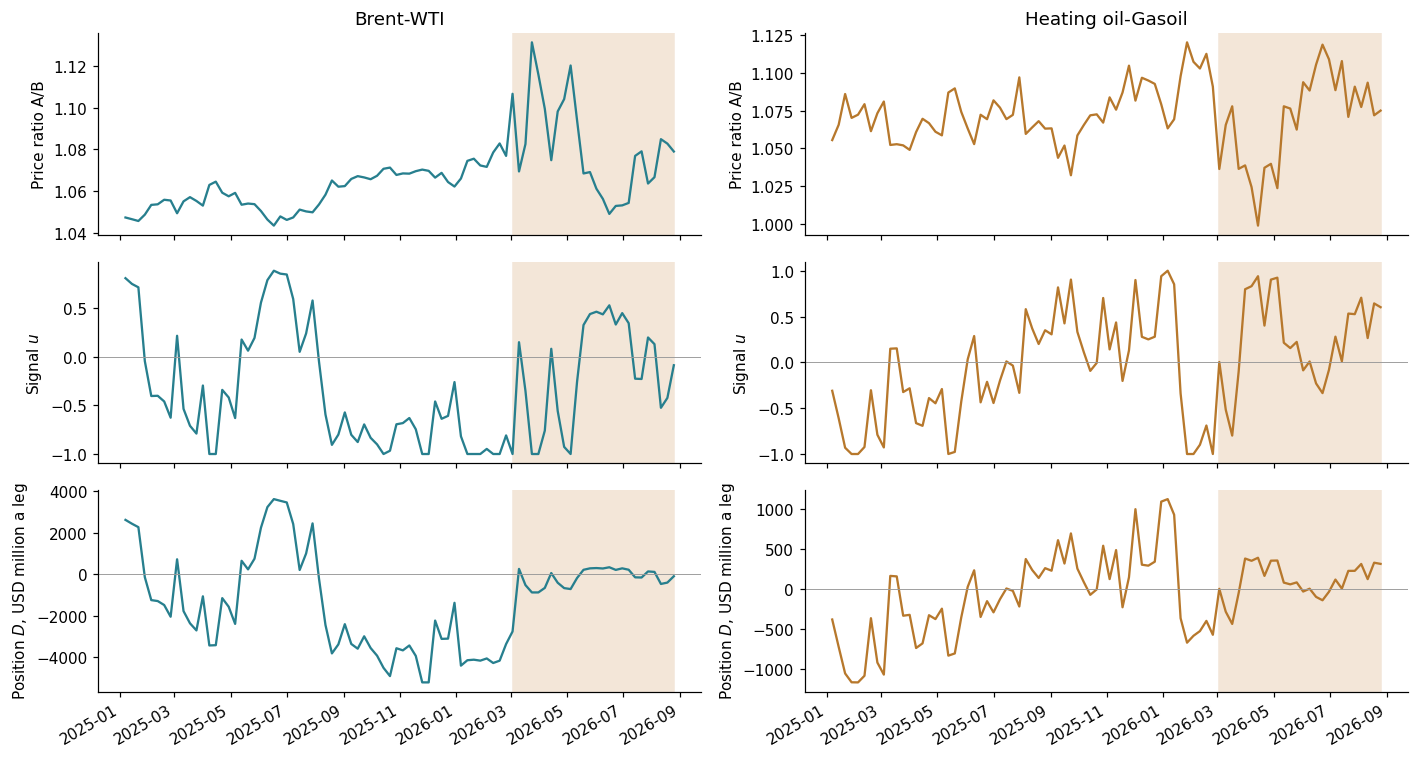

In [2]:
T = ct.trend_panel(DATA, PAPER_DATA, END)
generic, meta = sp.load_energy(PAPER_DATA)
panels = {pair: sp.spread_panel(generic, meta, pair, T.d_mm.index) for pair in sp.PAIRS}
pair_flow = pd.concat([P.flow for P in panels.values()], axis=1)

rows = {}
for pair, P in panels.items():
    a, b = P.legs
    rule_pnl = P.dollars.shift(1) * P.ret
    legs = P.daily[['ret_a', 'ret_b']].resample('W-TUE').sum().reindex(P.ret.index)[START:END]
    row = {f'Price ratio A/B, {p}': P.ratio[s:e].mean() for p, (s, e) in PERIODS.items()}
    row |= {f'Weekly vol, %, {p}': 100 * P.vol[s:e].mean() for p, (s, e) in PERIODS.items()}
    row |= {'ρ(return A, return B)': legs['ret_a'].corr(legs['ret_b']),
            'Slope of return A on return B': np.polyfit(legs['ret_b'], legs['ret_a'], 1)[0],
            'ρ(spread return, mean return of the legs)': P.ret[START:END].corr(legs.mean(axis=1)),
            'Daily return autocorrelation': P.daily['ret'][START:END].autocorr(1), 'Weekly return autocorrelation': P.ret[START:END].autocorr(1),
            'Weeks with all three signals capped, %': 100 * (P.signals[START:END].abs() >= sp.CAP).all(axis=1).mean(),
            'Rule Sharpe ratio, 2011–2025': sharpe(rule_pnl, START, '2025'), 'Rule Sharpe ratio, Mar–Aug 2026': sharpe(rule_pnl, '2026-03-01', END),
            'ρ(spread flow, trend flow), leg A': P.flow[a][START:END].corr(T.d_pos[a][START:END]),
            'ρ(spread flow, trend flow), leg B': P.flow[b][START:END].corr(T.d_pos[b][START:END]),
            'Mean |D|, USD million, 2025': P.dollars['2025'].abs().mean() / 1e6,
            'Mean |D|, USD million, Mar–Aug 2026': P.dollars['2026-03-01':END].abs().mean() / 1e6}
    rows[pair] = row
construction = pd.DataFrame(rows)
display(construction.round(2))

fig, axes = plt.subplots(3, 2, figsize=(13, 7), sharex=True)
for column, (pair, P) in enumerate(panels.items()):
    for ax, series, label in zip(axes[:, column], [P.ratio, P.signal, P.dollars / 1e6],
                                 ['Price ratio A/B', 'Signal $u$', 'Position $D$, USD million a leg']):
        ax.plot(series['2025':END], color=COLORS[pair])
        ax.axvspan(pd.Timestamp(WAR_START), pd.Timestamp(END), color=COLORS['war'], zorder=0)
        ax.set_ylabel(label)
    for ax in axes[1:, column]:
        ax.axhline(0, color='0.6', lw=0.6)
    axes[0, column].set_title(pair)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT / 'spread_signal_position.png', dpi=160)
plt.show()

**Observed.**

| | Brent − WTI | Heating oil − gasoil |
|---|---|---|
| Price ratio A/B, 2011–2019 / 2020–2025 / May–Aug 2026 | 1.10 / 1.06 / 1.07 | 1.03 / 1.07 / 1.08 |
| Weekly vol, %, same periods | 1.48 / 0.96 / 1.95 | 1.27 / 1.78 / 3.29 |
| $\rho$(return A, return B); slope of A on B | 0.94; 0.84 | 0.95; 0.96 |
| $\rho$(spread return, mean return of the legs) | −0.34 | 0.02 |
| Return autocorrelation, daily / weekly | 0.02 / −0.20 | −0.45 / −0.20 |
| Rule Sharpe ratio, 2011–2025 / Mar–Aug 2026 | −0.07 / 0.14 | 1.25 / 1.48 |
| $\rho$(spread flow, trend flow), leg A / leg B | 0.23 / −0.33 | −0.14 / −0.05 |
| Mean $\lvert D\rvert$, USD million, 2025 / Mar–Aug 2026 | 2,536 / 447 | 434 / 191 |

- All three signals are capped in 11.8% and 4.7% of weeks.
- Brent − WTI is not neutral to the oil price. Brent moves 0.84% for each 1% in WTI, so the spread return falls when oil rises, and the rule's WTI flow correlates −0.33 with WTI's trend flow.
- Gasoil settles in London about three hours before heating oil in New York. The negative daily autocorrelation and the Sharpe ratio of heating oil − gasoil are consistent with this timing gap alone.

## 2. Four markets together

Brent, WTI, heating oil and gasoil in one long-short portfolio, all in the delivery month Brent holds. Each market is traded against the equal-weighted basket of the four ($N=4$):

1. **Relative return.** $\tilde r_{m,t}=r_{m,t}-\frac1N\sum_j r_{j,t}$.
2. **Signal.** $u_{m,t}$ as in Section 1, on the cumulated $\tilde r_m$ and its volatility $\tilde\sigma_m$.
3. **Position.** One dollar of "market $m$ minus the basket" is one dollar long $m$ and $1/N$ dollars short every market. With $G_{m,t}=u_{m,t}\cdot(\text{risk}/N)/(\tilde\sigma_{m,t}\sqrt{52})$, the dollars held in market $m$ are

$$D_{m,t}=G_{m,t}-\frac1N\sum_jG_{j,t},\qquad\sum_mD_{m,t}=0.$$

With $N=2$ this is exactly the pair of Section 1.

,ICE Brent,CME WTI,CME Heating oil,ICE Gasoil
"Weekly vol of the relative return, %",0.99,1.42,1.09,1.32
"ρ(relative return, basket return)",0.14,0.28,-0.22,-0.27
Weekly autocorrelation of the relative return,-0.06,-0.15,-0.07,-0.19
"ρ(basket flow, pair flow)",0.10,0.50,0.37,0.55
"ρ(basket flow, trend flow)",-0.27,-0.38,0.01,0.02
"Mean |D|, USD million, 2025",169.62,178.99,224.58,147.60
"Mean |D|, USD million, Mar–Aug 2026",141.82,106.85,134.64,115.59


Rule Sharpe ratio: 0.40 over 2011–2025, -1.61 over Mar–Aug 2026; without gasoil's leg: 0.35 over 2011–2025


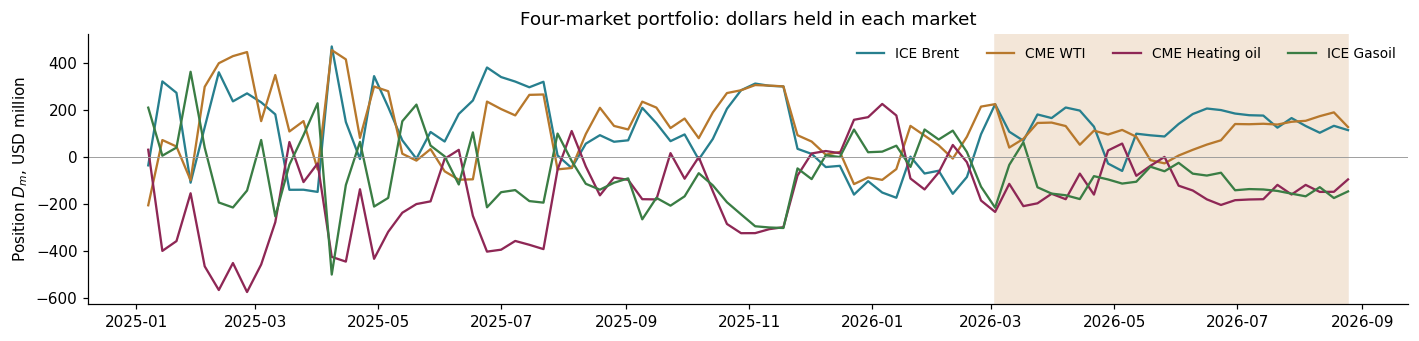

In [3]:
basket = sp.basket_panel(generic, meta, T.d_mm.index)
basket_return = basket.returns.mean(axis=1)

rows = {}
for m in sp.BASKET:
    w = slice(START, END)
    rows[ct.NAMES[m]] = {'Weekly vol of the relative return, %': 100 * basket.vol[m][w].mean(),
                         'ρ(relative return, basket return)': basket.relative[m][w].corr(basket_return[w]),
                         'Weekly autocorrelation of the relative return': basket.relative[m][w].autocorr(1),
                         'ρ(basket flow, pair flow)': basket.flow[m][w].corr(pair_flow[m][w]),
                         'ρ(basket flow, trend flow)': basket.flow[m][w].corr(T.d_pos[m][w]),
                         'Mean |D|, USD million, 2025': basket.dollars[m]['2025'].abs().mean() / 1e6,
                         'Mean |D|, USD million, Mar–Aug 2026': basket.dollars[m]['2026-03-01':END].abs().mean() / 1e6}
basket_table = pd.DataFrame(rows)
display(basket_table.round(2))
print(f"Rule Sharpe ratio: {sharpe(basket.rule_return, START, '2025'):.2f} over 2011–2025, "
      f"{sharpe(basket.rule_return, '2026-03-01', END):.2f} over Mar–Aug 2026; "
      f"without gasoil's leg: {sharpe((basket.dollars.shift(1) * basket.returns).drop(columns='GASOIL').sum(axis=1, min_count=3), START, '2025'):.2f} over 2011–2025")

fig, ax = plt.subplots(figsize=(13, 3.2))
for m in sp.BASKET:
    ax.plot(basket.dollars[m]['2025':END] / 1e6, color=COLORS[m], label=ct.NAMES[m])
ax.axvspan(pd.Timestamp(WAR_START), pd.Timestamp(END), color=COLORS['war'], zorder=0)
ax.axhline(0, color='0.6', lw=0.6)
ax.set(ylabel='Position $D_m$, USD million', title='Four-market portfolio: dollars held in each market')
ax.legend(frameon=False, ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT / 'basket_position.png', dpi=160)
plt.show()

**Observed.** 2011–2026 unless stated.

| | Brent | WTI | Heating oil | Gasoil |
|---|---|---|---|---|
| Weekly vol of $\tilde r$, % | 0.99 | 1.42 | 1.09 | 1.32 |
| $\rho(\tilde r,$ basket return$)$ | 0.14 | 0.28 | −0.22 | −0.27 |
| Weekly autocorrelation of $\tilde r$ | −0.06 | −0.15 | −0.07 | −0.19 |
| $\rho$(four-market flow, pair flow) | 0.10 | 0.50 | 0.37 | 0.55 |
| $\rho$(four-market flow, trend flow) | −0.27 | −0.38 | 0.01 | 0.02 |
| Mean $\lvert D\rvert$, USD million, 2025 / Mar–Aug 2026 | 170 / 142 | 179 / 107 | 225 / 135 | 148 / 116 |

- Rule Sharpe ratio: 0.40 over 2011–2025 (0.35 without gasoil's leg), −1.61 over Mar–Aug 2026.
- Crude gains on the basket when oil rises and products lose, so the crude flows correlate −0.27 and −0.38 with their trend flows.
- Brent's flow is nearly unrelated to its pair flow ($\rho$ = 0.10).
- June–August 2026 (13 weeks): long Brent and WTI and short heating oil and gasoil in every week, on average +133, +98, −120 and −111 USD million over May–August. The portfolio bets that crude catches up with products.

## 3. Baseline network with the spread flow

The Insight 177 network is refitted weekly from 2015 to August 2026, with the same windows, warm starts and seed as the replication (`sg.run_decomposition`). Its nowcast is kept fixed and its error is regressed on the spread flow of the same week, from the pairs or from the four-market portfolio:

$$\widehat{\Delta MM}^{corr}_{m,t}=\widehat{\Delta MM}^{NN}_{m,t}+s_{m,t}\,\gamma_{m,t}\,\frac{f_{m,t}}{s_{m,t}},$$

with $s$ the lagged position scale and $\gamma_{m,t}$ a ridge fit (penalty 0.1) per market on the previous 104 out-of-sample errors, as the carry correction in `nn_carry_volatility.ipynb`. $f=0$ in RBOB and natural gas. $\gamma>0$: MM trades with the mean-reversion rule.

In [4]:
config = ReplicationConfig(data_dir=PAPER_DATA, basis='futures_only', train_weeks=104, seed=7, evaluation_end='2026-12-31')
panel, _ = sg.load_weekly_data(config)
decomposition, _ = sg.run_decomposition(panel, config)
nn = decomposition.merge(panel[sg.KEYS + ['actual_change', 'mm_std_lag', 'panel_date']], on=sg.KEYS, validate='one_to_one')
nn['predicted_change'] = nn['mm_std_lag'] * (nn['trend_cur'] - nn['trend_prev'])
nn['normalized_error'] = (nn['actual_change'] - nn['predicted_change']) / nn['mm_std_lag']

corrected = {}
for name, flow in {'pair': pair_flow, 'basket': basket.flow}.items():
    flow = flow.reindex(columns=sg.MARKETS, fill_value=0.0).stack().rename('flow').rename_axis(sg.KEYS).reset_index()
    design = nn.merge(flow, on=sg.KEYS, how='left')
    design['flow'] = design['flow'] / design['mm_std_lag']
    out, _ = sg.rolling_ridge(design, ['flow'], 'normalized_error', 'predicted_change', pooled=False)
    corrected[name] = out.rename(columns={'prediction': 'corrected_change'})

In [5]:
NN_PERIODS = {'2017–2025': ('2017-01-01', '2025-12-31'), 'Mar–Apr 2026': ('2026-03-01', '2026-04-30'), 'May–Aug 2026': ('2026-05-01', END)}
GROUPS = {ct.NAMES[m]: [m] for m in sp.BASKET} | {'Six markets': sg.MARKETS}
r2 = lambda d, column='predicted_change': sg.score(d, column)['R² (%)']
rows = {}
for period, (start, end) in NN_PERIODS.items():
    for group, markets in GROUPS.items():
        row = {}
        for name, out in corrected.items():
            d = sg.common_sample(out, start, end)
            d = d[d['market'].isin(markets)]
            row |= {'NN': r2(d), f'NN + {name} flow': r2(d, 'corrected_change'),
                    f'ρ(NN error, {name} flow)': d['normalized_error'].corr(d['flow']) if len(markets) == 1 else np.nan}
        rows[period, group] = row
nn_table = pd.DataFrame(rows).T[['NN', 'NN + pair flow', 'NN + basket flow', 'ρ(NN error, pair flow)', 'ρ(NN error, basket flow)']]
display(nn_table.round(2))

by_year = {}
for name, out in corrected.items():
    sample = sg.common_sample(out, '2017-01-01', END)
    for group, markets in GROUPS.items():
        d = sample[sample['market'].isin(markets)]
        by_year[name, group] = d.groupby(d['panel_date'].dt.year).apply(lambda g: r2(g, 'corrected_change') - r2(g), include_groups=False)
by_year = pd.DataFrame(by_year).T
print('R² gain from the spread flow by year, percentage points (2026: January to August)')
display(by_year.round(1))

NN  NN + pair flow  NN + basket flow  \
2017–2025    ICE Brent         50.17           50.25             50.53   
             CME WTI           40.19           42.70             41.10   
             CME Heating oil   34.96           34.50             36.52   
             ICE Gasoil        47.38           46.79             46.93   
             Six markets       44.90           45.60             45.29   
Mar–Apr 2026 ICE Brent          7.63            4.96              7.41   
             CME WTI         -102.22          -73.17            -96.63   
             CME Heating oil -117.15         -118.08            -91.74   
             ICE Gasoil        -4.60          -13.27             -5.98   
             Six markets       -3.79           -2.92             -3.32   
May–Aug 2026 ICE Brent         71.37           71.78             71.31   
             CME WTI          -82.88          -74.76            -83.46   
             CME Heating oil    6.91            7.62             12.72   
             ICE Gasoil      -264.67         -267.50           -264.56   
             Six markets       43.46           44.41             43.39   

                              ρ(NN error, pair flow)  ρ(NN error, basket flow)  
2017–2025    ICE Brent                         -0.15                     -0.18  
             CME WTI                           -0.28                     -0.16  
             CME Heating oil                   -0.06                     -0.14  
             ICE Gasoil                        -0.03                     -0.03  
             Six markets                         NaN                       NaN  
Mar–Apr 2026 ICE Brent                          0.10                     -0.63  
             CME WTI                           -0.52                     -0.50  
             CME Heating oil                    0.09                     -0.34  
             ICE Gasoil                         0.61                      0.19  
             Six markets                         NaN                       NaN  
May–Aug 2026 ICE Brent                         -0.50                     -0.08  
             CME WTI                           -0.60                      0.16  
             CME Heating oil                   -0.26                     -0.20  
             ICE Gasoil                         0.14                      0.01  
             Six markets                         NaN                       NaN

R² gain from the spread flow by year, percentage points (2026: January to August)


panel_date              2017  2018  2019  2020  2021  2022  2023  2024  2025  \
pair   ICE Brent       -10.4  -0.7  -1.2   6.5  -3.7  -0.3   0.9  -0.2   2.4   
       CME WTI          -0.1   2.2   2.3  -4.7   5.0   9.1  14.4   3.2  -2.8   
       CME Heating oil   1.3  -2.8   1.2  -1.4   3.4   0.8  -3.7  -1.1  -0.4   
       ICE Gasoil       -0.9   0.4  -1.6  -2.8   0.1  -0.2  -0.2   0.0  -0.8   
       Six markets      -2.4   0.3   0.5   0.8  -0.1   1.9   4.9   0.7   0.8   
basket ICE Brent         3.0   2.6  -0.6   8.4 -26.3   7.3  -0.1  -1.1  -0.9   
       CME WTI           0.9   2.8   4.4  -6.0   2.5   2.3   2.4   5.7  -8.7   
       CME Heating oil   0.2  -0.3   1.6  -2.0   2.6  -1.8   0.4   0.8   9.2   
       ICE Gasoil       -0.6   0.0  -1.3  -1.3  -1.0  -0.5   2.4  -1.2   0.2   
       Six markets       1.0   1.3   1.4   1.2  -7.4   4.4   0.8   0.8  -1.9   

panel_date              2026  
pair   ICE Brent        -1.2  
       CME WTI          -3.2  
       CME Heating oil  -3.1  
       ICE Gasoil       -1.1  
       Six markets      -1.0  
basket ICE Brent        -0.2  
       CME WTI           3.0  
       CME Heating oil   0.4  
       ICE Gasoil        0.4  
       Six markets       0.1

**Observed.** $R^2$ in percent: network alone / with the pair flow / with the four-market flow.

| | 2017–2025 | Mar–Apr 2026 ($n=9$) | May–Aug 2026 ($n=17$) |
|---|---|---|---|
| WTI | 40.19 / 42.70 / 41.10 | −102.22 / −73.17 / −96.63 | −82.88 / −74.76 / −83.46 |
| Brent | 50.17 / 50.25 / 50.53 | 7.63 / 4.96 / 7.41 | 71.37 / 71.78 / 71.31 |
| Heating oil | 34.96 / 34.50 / 36.52 | −117.15 / −118.08 / −91.74 | 6.91 / 7.62 / 12.72 |
| Gasoil | 47.38 / 46.79 / 46.93 | −4.60 / −13.27 / −5.98 | −264.67 / −267.50 / −264.56 |
| Six markets | 44.90 / 45.60 / 45.29 | −3.79 / −2.92 / −3.32 | 43.46 / 44.41 / 43.39 |

- Sign, 2017–2025: $\rho$(NN error, $f$) = −0.28 in WTI, −0.15 in Brent and −0.06 in heating oil for the pair flow; −0.16, −0.18 and −0.14 for the four-market flow. Gasoil: −0.03 for both.
- Pair flow, WTI gain by year, 2017–2025: −0.1, 2.2, 2.3, −4.7, 5.0, 9.1, 14.4, 3.2, −2.8 points. January–August 2026: −3.2.
- Four-market flow, six-market gain by year, 2017–2025: 1.0, 1.3, 1.4, 1.2, −7.4, 4.4, 0.8, 0.8, −1.9 points. Brent in 2021: −26.3.
- The crude flows correlate with their own trend flows (pairs: 0.23 in Brent, −0.33 in WTI; four markets: −0.27, −0.38), so the crude gains are not attributable to spreads alone.
- No test of the gains is run.

## Not yet run

1. Hedge ratios that remove the oil-price tilt: Brent moves 0.84% for each 1% in WTI, and crude gains on products when oil rises.
2. $\Delta MM^A-\Delta MM^B$ against the spread flow, next to the difference of the two trend flows.
3. A test of the gains (Clark-West, as in `leadlag_network.ipynb`), and the signal inside the network instead of as a correction.
4. The rule with the sign reversed (spread momentum), since $\gamma<0$; gasoil on prices taken at the same time of day; RBOB as a fifth market.

## Save results

In [6]:
for pair, P in panels.items():
    name = pair.lower().replace(' ', '_').replace('-', '_')
    (pd.DataFrame({'ratio': P.ratio, 'ret': P.ret, 'vol': P.vol, 'signal': P.signal, 'dollars': P.dollars})
     .join([P.contracts.add_prefix('contracts_'), P.flow.add_prefix('flow_')]).loc[START:END].to_csv(OUTPUT / f'{name}_panel.csv'))
pd.concat({'signal': basket.signal, 'dollars': basket.dollars, 'contracts': basket.contracts, 'flow': basket.flow}, axis=1).loc[START:END].to_csv(OUTPUT / 'basket_panel.csv')
construction.to_csv(OUTPUT / 'construction.csv')
basket_table.to_csv(OUTPUT / 'basket.csv')
for name, out in corrected.items():
    out.to_csv(OUTPUT / f'nn_with_{name}_flow.csv', index=False)
nn_table.to_csv(OUTPUT / 'nn_r2.csv')
by_year.to_csv(OUTPUT / 'nn_gain_by_year.csv')

## References

- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), [Momentum Trading and Managed Money Positioning in Energy](https://www.oxfordenergy.org/wpcms/wp-content/uploads/2026/03/Insight-177-Money-Positioning-in-Energy.pdf), OIES Insight 177, for the network.
- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), *Shifting Oil Market Positioning During the Strait of Hormuz Crisis*, OIES Energy Comment, October (`references/`).
- Kestner, L. N. (2020), *Replicating CTA Positioning: An Improved Method*, [SSRN 3674828](https://ssrn.com/abstract=3674828), for the capped, volatility-scaled signal and the sizing.